# Cell embeddings and clusters across modalities

This tutorial embeds the same cells by their transcriptome and by their single-cell contact maps, clusters
them, scores the clusters against published cell types (ARI / NMI) and lists marker features.  It then embeds
immunofluorescence (IF) signals that an imaging experiment measured at every DNA spot, and shows how the
embeddings are stored so that the web browser can show them.  Every step is one call on the `ChromData`:
the data come from `uchrom.datasets.load`, the methods of `uchrom.emb` read what they need from it (columns of
`cells`, the linked count matrix, the linked contact maps, the spot tracks) and store their results on it.

- **Modules**: `uchrom.datasets.load`; `uchrom.emb`: `add_gene_counts`, `embed_cells`, `cluster_cells`,
  `marker_features`, `embed_contacts` (scHiCluster), `tfidf_lsi`, `aggregate_tracks`, and to score and show
  the results `cluster_agreement`, `knn_purity`, `plot_embedding` (`uchrom.emb.hic.schicluster_impute` for one
  cell); `chromdata.ChromData`, `uchrom_browser.data`.
- **Data**: the scHiCAR mouse frontal cortex: RNA, ATAC and chromatin contacts measured in the same 5,313 nuclei,
  with 22 published cell types.  Wei et al. 2026, *Nat. Biotechnol.*, GEO GSE305439.  The second dataset is the
  Takei et al. 2025 (*Nature*) cerebellum DNA seqFISH+ with 48 IF channels: replicate 1, 1,799 cells (Zenodo
  7693825).  Both are stores of the public U-Chrom atlas, read over HTTP: `ds.load("schicar_mouse_cortex")`
  (built by `apps/atlas/recipes/build_schicar_mop.py`, with embedded copies of the contact maps and of the RNA
  count matrix) and `ds.load("takei2025_cerebellum")` (built by
  `apps/atlas/recipes/build_takei2025_cerebellum.py`).  They open backed: only the tables, contact maps and
  tracks the notebook uses are fetched, nothing has to be downloaded or built beforehand.
- **Runtime**: 3–4 min on a laptop CPU with a good connection; most of it is reading over HTTP (the
  contact maps of section 6 and the IF tracks of section 8).  We use 2,000 of the 5,313 scHiCAR cells, chosen at
  random, so that the contact-map step takes about a minute.

In [1]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from chromdata import ChromData
import uchrom.datasets as ds
from uchrom import emb

plt.rcParams["figure.dpi"] = 90
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="IProgress not found")   # tqdm, imported by umap-learn

OUT = Path("_out"); OUT.mkdir(exist_ok=True)   # outputs: tutorials/_out/ (ignored by git)
T0 = time.time()

## 1. Load the scHiCAR store and pick the cells

`ds.load("schicar_mouse_cortex")` opens the atlas store.  It holds no 3-D coordinates, so it has no spots.  It
holds one row per nucleus in `cells`, with the published `cell_type`, QC numbers, `rna.<gene>` counts and ATAC
gene activity `atac.<gene>`.  It also stores embeddings in `cellm`, and **links** to two files:

- a `.scool` file with one contact map per cell at 1 Mb;
- an `.h5ad` file with the full RNA count matrix.

A linked file normally stays outside the store (see the *Linked modalities* guide).  An atlas store must stand
alone on object storage, so it also carries **embedded copies** of its linked files (`embedded/contacts/`,
`embedded/anndata/`).  The link records stay in `uns`, and a reader uses the embedded copy when the file is not
there: `cd.linked_adata` reads the AnnData, `cd.linked_scool_path(...)` exports the maps of some cells to a
`.scool`, `cd.load_linked_scool(key=..., cell=...)` one cell's map.  This store also embeds the merged and
per-cell-type pseudo-bulk maps (`uns["linked_cool"]`).

`get_cells` keeps 2,000 random cells, with their metadata, their rows of the stored embeddings and the links.
Among the stored embeddings we use the published UMAP, and `atac_lsi`, the ATAC embedding that the build recipe
computed from 100 kb genome bins of all 5,313 cells (the raw ATAC fragments, 1.35 GB, are not needed here); the
RNA and Hi-C embeddings are computed again below.  Each cell type also gets a coarse class: excitatory neurons,
inhibitory neurons or non-neuronal cells.

In [2]:
full = ds.load("schicar_mouse_cortex")       # the atlas store, backed over HTTP: cells, cellm and uns are read at open
print(f"{full.n_cells:,} cells, {full.cells['cell_type'].nunique()} published cell types, "
      f"{sum(c.startswith('rna.') for c in full.cells.columns)} rna.* columns")
print("cellm:", list(full.cellm))
print("linked:", full.uns["linked_scool"]["per_cell"]["path"], "and", full.uns["linked_anndata"]["path"])
embedded = full.embedded_links()
print(f"embedded copies: {len(embedded['contacts'])} contact maps (per_cell, all_cells and one per cell type), "
      f"{len(embedded['anndata'])} AnnData")

N_CELLS = 2000
keep = np.sort(np.random.default_rng(0).choice(full.n_cells, N_CELLS, replace=False))
cd = full.get_cells(full.cells.index[keep])   # in memory: these cells, their stored embeddings, the links

CLASS = {**dict.fromkeys(["L23IT.1", "L23IT.2", "L23IT.3", "L45IT", "L5IT", "L6IT", "L6CT", "L56NP", "PT", "CLA"],
                         "excitatory"),
         **dict.fromkeys(["Pvalb", "Sst", "Vip", "Lamp5", "D2MSN"], "inhibitory"),
         **dict.fromkeys(["Astro", "Oligo", "OPC", "MGL", "Endo", "Peri", "LMC"], "non-neuronal")}
cd.cells["cell_class"] = cd.cells["cell_type"].map(CLASS)
y_type = cd.cells["cell_type"].astype(str).to_numpy()
y_class = cd.cells["cell_class"].to_numpy()
print(cd.n_cells, "cells kept;", pd.Series(y_class).value_counts().to_dict())

5,313 cells, 22 published cell types, 500 rna.* columns
cellm: ['paper_umap', 'rna_pca', 'rna_tsne', 'rna_umap', 'atac_lsi', 'atac_tsne', 'atac_umap', 'hic_pca', 'hic_tsne', 'hic_umap']
linked: contacts_cells_1Mb.scool and schicar_mop_rna.h5ad


embedded copies: 24 contact maps (per_cell, all_cells and one per cell type), 1 AnnData
2000 cells kept; {'excitatory': 1305, 'non-neuronal': 448, 'inhibitory': 247}


## 2. RNA: choose variable genes from the linked count matrix

The store's 500 `rna.*` columns were ranked by raw dispersion (variance / mean), which favours genes with low
expression.  `add_gene_counts` replaces them: it reads every gene's UMI counts from the linked AnnData
(`cd.linked_adata`; on the atlas store the embedded copy, read over HTTP on first access: 5,313 cells × 28,783
genes, sparse), matches its rows to our cells and picks 2,000 highly variable genes with the usual Seurat recipe
(`highly_variable_genes`: log-normalise, then z-score the dispersion within 20 bins of mean expression).  The
genes become `rna.<gene>` columns of `cd.cells`, where `embed_cells` and `marker_features` find them; the
selection is recorded in `cd.results["rna.genes"]`.

`embed_cells(cd, source="rna", methods=("pca",))` normalises the `rna.*` counts (library size, `log1p`, z-score
per gene: `normalize_counts`) and keeps their PCs.  We run it on the stored genes first, to compare the two gene
sets by how well 30 PCs keep cells of one type together (k-nearest-neighbour purity, k = 10, `knn_purity`).

In [3]:
emb.embed_cells(cd, source="rna", methods=("pca",), library_size=True, n_pcs=30)     # the store's 500 genes
purity_500 = emb.knn_purity(cd.cellm["rna_pca"], y_type)

genes = emb.add_gene_counts(cd, n_top=2000)        # reads cd.linked_adata; replaces the rna.* columns
print(f"linked RNA: {cd.linked_adata.n_vars:,} genes; median UMIs per cell {cd.cells['n_counts_rna'].median():,.0f}")
print("first HVGs:", ", ".join(genes[:12]))
cd.results["rna.genes"].head(3)

linked RNA: 28,783 genes; median UMIs per cell 17,918
first HVGs: Plp1, Mertk, Slc1a3, Zfp536, Atp1a2, Sox2ot, Daam2, Ptprz1, Dock10, Htra1, Flt1, Adarb2


,gene,mean,dispersion,dispersion_z,frac_cells
0,Plp1,0.320560,0.707068,6.916523,0.2650
1,Mertk,0.364822,0.579316,6.202236,0.2740
2,Slc1a3,0.362252,0.513845,5.836178,0.2945


## 3. `embed_cells`: PCA, t-SNE and UMAP

`embed_cells(cd, source="rna")` selects the numeric `rna.*` columns, now the 2,000 variable genes.  Count
features are normalised with `normalize_counts`; `library_size=True` suits transcriptome-wide data.  The function
then runs PCA on the normalised matrix, and t-SNE and UMAP on the PCs.  The results are `cd.cellm["rna_pca"]`,
`["rna_tsne"]` and `["rna_umap"]`, with rows in the order of `cd.cells`.  The parameters go to
`cd.uns["embeddings"]`.  `plot_embedding` draws an embedding coloured by a `cells` column.

{'rna_pca': (2000, 30), 'rna_tsne': (2000, 2), 'rna_umap': (2000, 2)} in 25 s
library-size (median total), log1p, z-score per feature | 2000 features | variance of PC1-5: [0.05  0.029 0.026 0.021 0.018]
kNN-10 purity of cell types: 2,000 HVGs 0.859 | the store's 500 genes 0.411


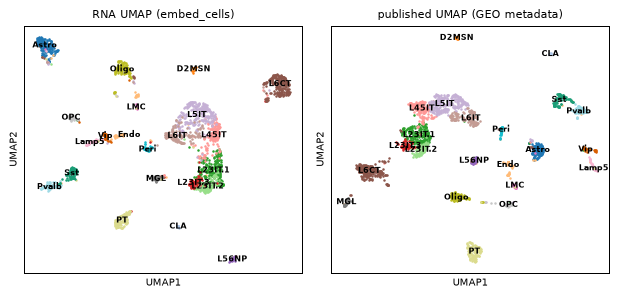

In [4]:
t = time.time()
out = emb.embed_cells(cd, source="rna", library_size=True, n_pcs=30)
print({k: v.shape for k, v in out.items()}, f"in {time.time() - t:.0f} s")
meta = cd.uns["embeddings"]["rna_pca"]
print(meta["normalization"], "|", meta["n_features"], "features | variance of PC1-5:",
      np.round(meta["explained_variance_ratio"][:5], 3))
print(f"kNN-10 purity of cell types: 2,000 HVGs {emb.knn_purity(cd.cellm['rna_pca'], y_type):.3f} "
      f"| the store's 500 genes {purity_500:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(7, 3.4))
emb.plot_embedding(cd, "rna_umap", "cell_type", ax=axes[0], title="RNA UMAP (embed_cells)")
emb.plot_embedding(cd, "paper_umap", "cell_type", ax=axes[1], title="published UMAP (GEO metadata)")
fig.tight_layout()

## 4. `cluster_cells`: Leiden clusters and agreement with the published cell types

`cluster_cells` builds a k-nearest-neighbour graph (k = 15) on an embedding and partitions it with the Leiden
algorithm.  The labels are stored as a categorical column of `cd.cells` and the parameters in
`cd.uns["clusters"]`.  `cluster_agreement` compares them with the 22 published cell types and with the three
coarse classes, using the adjusted Rand index (ARI; 0 = chance, 1 = identical) and normalised mutual information
(NMI).

In [5]:
lab_rna = emb.cluster_cells(cd, use="rna_pca", resolution=1.0, key_added="leiden_rna")
print(f"{lab_rna.nunique()} RNA clusters")
display(pd.DataFrame({"vs cell types": emb.cluster_agreement(lab_rna, y_type),
                      "vs coarse classes": emb.cluster_agreement(lab_rna, y_class)}).T.round(3))

# each cluster: size, its most frequent published type and that type's share
tab = pd.crosstab(lab_rna, cd.cells["cell_type"])
summary = pd.DataFrame({"n_cells": tab.sum(axis=1), "main_type": tab.idxmax(axis=1),
                        "share": (tab.max(axis=1) / tab.sum(axis=1)).round(2)})
summary.T

17 RNA clusters


,ARI,NMI
vs cell types,0.675,0.804
vs coarse classes,0.144,0.414


leiden_rna,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
n_cells,256,222,205,173,163,160,116,115,108,95,79,74,60,54,49,37,34
main_type,L23IT.1,L6IT,L6CT,L5IT,L23IT.2,Astro,Oligo,PT,L45IT,Lamp5,Pvalb,Sst,D2MSN,MGL,OPC,Peri,L56NP
share,0.71,0.57,0.99,0.92,0.43,0.91,0.92,0.98,0.94,0.43,0.92,0.99,0.4,0.83,0.92,0.89,0.94


Most clusters map to one published type: more than 80 % of their cells share it.  The exceptions are
the L2/3 IT subgroups, L6 IT and two small interneuron groups (Lamp5, D2MSN), which the clusters of 2,000 cells
at resolution 1 mix with their neighbours.  The published labels come from a finer analysis of the full
transcriptome of all cells.  So the ARI is well below 1, while the NMI stays high.

## 5. `marker_features`: what distinguishes each group

`marker_features` ranks the `prefix` columns of `cd.cells` by the difference of the mean of `log1p(value)`
between a group and all other cells.  Applied to the published types, it recovers known markers:

- *Plp1* / *Mobp* / *St18* in oligodendrocytes and *Ptprz1* in OPCs;
- *Slc1a2* / *Slc1a3* in astrocytes and *Inpp5d* / *Dock2* in microglia;
- *Kcnc2* in Pvalb interneurons;
- *Foxp2* in L6 corticothalamic neurons and *Tshz2* in L5/6 near-projecting neurons.

Applied to the Leiden clusters, it describes clusters that have no label yet; for example, *Cux2* comes out
for the L2/3 IT cluster.

In [6]:
by_type = emb.marker_features(cd, "cell_type", prefix="rna.", n_top=4)
show = ["Oligo", "OPC", "Astro", "MGL", "Endo", "Peri", "Pvalb", "Sst", "Vip", "L6CT", "PT", "L56NP"]
display(pd.DataFrame({t: by_type[t] for t in show}).rename_axis("rank"))

by_cluster = emb.marker_features(cd, "leiden_rna", prefix="rna.", n_top=4)
pd.DataFrame({f"{c} ({summary.loc[c, 'main_type']})": by_cluster[c] for c in summary.index[:8]}).rename_axis("rank")

,Oligo,OPC,Astro,MGL,Endo,Peri,Pvalb,Sst,Vip,L6CT,PT,L56NP
rank,,,,,,,,,,,,
0,Plp1,Lhfpl3,Gpc5,Tgfbr1,Bnc2,Flt1,Erbb4,Nxph1,Adarb2,Hs3st4,Tafa1,Tshz2
1,St18,Sox2ot,Slc1a2,Inpp5d,Fbxl7,Slco1a4,Nxph1,Grik1,Erbb4,Foxp2,Gm2164,Vwc2l
2,Mobp,Nxph1,Slc1a3,Lrmda,Eya2,Ebf1,Kcnc2,Synpr,Npas3,Zfpm2,Pex5l,Nxph1
3,Mbp,Ptprz1,Mertk,Dock2,Nxn,Mecom,Btbd11,Npas3,Zfp536,Grik3,Tcerg1l,Olfm3


,0 (L23IT.1),1 (L6IT),2 (L6CT),3 (L5IT),4 (L23IT.2),5 (Astro),6 (Oligo),7 (PT)
rank,,,,,,,,
0,Cux2,Galnt14,Hs3st4,Pcdh15,Epha6,Gpc5,Plp1,Tafa1
1,Lingo2,Sorcs3,Foxp2,Cpne4,Slit3,Slc1a2,St18,Gm2164
2,Rasgrf2,Il1rapl2,Zfpm2,Cntn5,March1,Mertk,Mbp,Pex5l
3,Unc5d,Grik3,Grik3,Zfp804b,Grm1,Slc1a3,Mobp,Tcerg1l


## 6. Contact maps: `embed_contacts` (scHiCluster) on the linked maps

The same nuclei also have a contact map.  `embed_contacts(cd, contacts="per_cell", method="schicluster")` embeds
the cells by the maps linked under `per_cell`, with the features of scHiCluster (Zhou et al. 2019, *PNAS*),
computed as the authors' code computes them (`impute_cpu` and `hicluster_cpu` of `schicluster` 1.3.2):

1. Read the 1 Mb intra-chromosomal map of each chromosome of each cell (chromosomes 1–19 and X: Y and M are
   left out by default) and take `log2(counts + 1)`.
2. Smooth it with a 3 × 3 mean filter.
3. Impute it by a random walk with restart (`uchrom.emb.hic.schicluster_impute`).
4. Keep the top 20 % of the entries of each cell's imputed map (set them to 1, the rest to 0).
5. Reduce each chromosome to PCs across cells, and concatenate the PCs of all chromosomes.  The authors' number of
   PCs, `int(0.2 · min(cells, bins²)) − 1`, is the default (`n_per_chrom=None`): 399 per chromosome for 2,000 cells,
   whose PCA takes about 7 minutes on 8 CPUs.  We keep 20 per chromosome (`n_per_chrom=20`).

`embed_cells` then runs PCA, t-SNE and UMAP on these features (`hic_pca`, `hic_tsne`, `hic_umap`).

The per-cell maps are embedded in the atlas store, partitioned by chromosome with the cells in order
(`embedded/contacts/per_cell`; layout in `packages/chromdata/spec.md`).  `embed_contacts` gets them with
`cd.linked_scool_path("per_cell", cells=..., trans=False)`: when the linked file is not there, the maps of the
cells asked for are exported once to a scratch `.scool`, reading each chromosome's partition once for all of
them (the contacts between chromosomes, which scHiCluster does not use, are left out).  With a local `.scool`
linked instead, the same call reads that file.

First, look at one cell: `load_linked_scool` exports its map from the store.  The raw map is very sparse, and
imputation spreads its contacts along the diagonal and into domains.

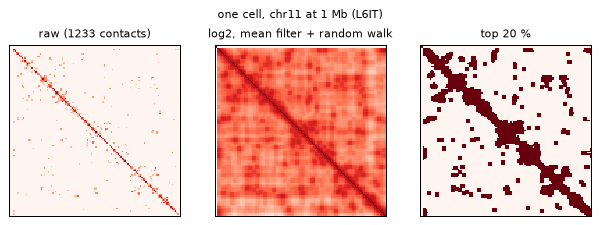

In [7]:
from uchrom.emb.hic import schicluster_impute

cell = cd.cells["n_contacts_hic"].sort_values().index[int(0.75 * cd.n_cells)]   # a cell at the 75th depth percentile
one = cd.load_linked_scool(key="per_cell", cell=cell)            # a cooler, exported from the embedded copy
raw = one.matrix(balance=False).fetch("chr11").astype(float)
imputed = schicluster_impute(raw, pad=1, rp=0.5)                # log2, 3 x 3 mean filter, random walk
binary = imputed > np.percentile(imputed, 80)                    # the top 20 % of all entries

fig, axes = plt.subplots(1, 3, figsize=(7, 2.5))
for ax, m, title in zip(axes, [np.log1p(raw), np.log(np.maximum(imputed, 1e-6)), binary],
                        [f"raw ({int(np.triu(raw).sum())} contacts)", "log2, mean filter + random walk", "top 20 %"]):
    ax.imshow(m, cmap="Reds", interpolation="none")
    ax.set_title(title, fontsize=9); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f"one cell, chr11 at 1 Mb ({cd.cells.loc[cell, 'cell_type']})", fontsize=9)
fig.tight_layout()

Now embed all 2,000 cells (the export over HTTP, then the features).  `embed_contacts` stores the embeddings
like `embed_cells` (registered as the Hi-C modality, with a description of the features), the number of
contacts each cell's features were computed from in `cd.cells["hic_n_cis_contacts"]`, its settings in
`cd.uns["hic"]` and the scHiCluster features themselves (2,000 × 400) in `cd.results["hic"]`.

In [8]:
t = time.time()
emb.embed_contacts(cd, contacts="per_cell", method="schicluster", n_per_chrom=20, n_pcs=20)
print(f"embed_contacts: {cd.uns['hic']['n_features']} scHiCluster features of {cd.uns['hic']['n_cells']:,} cells "
      f"in {time.time() - t:.0f} s")
print(cd.uns["embeddings"]["hic_pca"]["features"])
n_all = cd.cells["n_contacts_hic"].to_numpy()                    # all contacts per cell (stored)
n_cis = cd.cells["hic_n_cis_contacts"].to_numpy()                # intra-chromosomal, chr1-19 and X
assert (n_cis <= n_all).all()
print(f"{n_cis.sum():,} intra-chromosomal contacts used ({n_cis.sum() / n_all.sum():.0%} of all)")
r_depth = [round(float(np.corrcoef(cd.cellm["hic_pca"][:, j], np.log(n_all))[0, 1]), 2) for j in range(3)]
print("Pearson r of Hi-C PC1-3 with log(contacts):", r_depth)

lab_hic = emb.cluster_cells(cd, use="hic_pca", resolution=1.0, key_added="leiden_hic")
lab_hic2 = emb.cluster_cells(cd, use="hic_pca", resolution=0.3, key_added="leiden_hic_coarse")
display(pd.DataFrame({f"{lab_hic.nunique()} clusters (resolution 1) vs cell types": emb.cluster_agreement(lab_hic, y_type),
                      f"{lab_hic2.nunique()} clusters (resolution 0.3) vs coarse classes":
                          emb.cluster_agreement(lab_hic2, y_class)}).T.round(3))
pd.crosstab(lab_hic2, cd.cells["cell_class"]).rename_axis(index="leiden_hic_coarse", columns=None)

embed_contacts: 400 scHiCluster features of 2,000 cells in 177 s
scHiCluster: 1 Mb maps of 20 chromosomes (chr1–chrX); log2, 3x3 mean filter, random walk (rp=0.5), top 20% binarised, 20 PCs per chromosome
33,850,066 intra-chromosomal contacts used (74% of all)
Pearson r of Hi-C PC1-3 with log(contacts): [-0.11, 0.42, 0.44]


,ARI,NMI
5 clusters (resolution 1) vs cell types,0.104,0.223
2 clusters (resolution 0.3) vs coarse classes,0.550,0.505


,excitatory,inhibitory,non-neuronal
leiden_hic_coarse,,,
0,1274,235,49
1,31,12,399


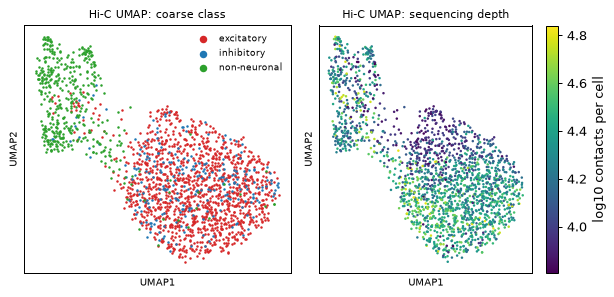

In [9]:
CLASS_COLORS = {"excitatory": "tab:red", "inhibitory": "tab:blue", "non-neuronal": "tab:green"}
fig, axes = plt.subplots(1, 2, figsize=(7, 3.4))
emb.plot_embedding(cd, "hic_umap", "cell_class", ax=axes[0], palette=CLASS_COLORS, annotate=False, legend=True,
                   title="Hi-C UMAP: coarse class")
emb.plot_embedding(cd, "hic_umap", np.log10(cd.cells["n_contacts_hic"]), ax=axes[1],
                   colorbar_label="log10 contacts per cell", title="Hi-C UMAP: sequencing depth")
fig.tight_layout()

At 1 Mb, single-cell contact maps separate neurons from non-neuronal cells, but not the finer neuronal
subtypes.  The fine-type ARI is therefore much lower than for RNA.  Within the neurons, the main gradients
follow the number of contacts per cell: PC2 and PC3 track sequencing depth (r above).

## 7. Sparse counts: `tfidf_lsi` and the agreement of the modalities

For sparse counts such as ATAC fragments, `embed_cells(..., normalization="tfidf")` (the default for
`source="atac"`) calls `tfidf_lsi`: TF-IDF, then truncated SVD (latent semantic indexing).  Component 1 is
dropped when it tracks sequencing depth.  The store's `atac.*` columns count fragments in the gene body + 2 kb
of 484 genes, and they show the depth effect clearly.  These windows hold few fragments per cell, so the
build recipe used 100 kb genome bins for the stored `atac_lsi` instead.

In [10]:
gact = cd.cells.filter(regex=r"^atac\.").to_numpy()           # the store's gene-activity counts
lsi, info = emb.tfidf_lsi(gact, n_components=30)
print(f"gene-activity counts: median {np.median(gact.sum(1)):.0f} fragments per cell in {gact.shape[1]} genes")
print("r(LSI component, log depth) for components 1-3:", np.round(info["depth_r"][:3], 2),
      "-> dropped", info["dropped"])
print(f"kNN-10 purity: gene-activity LSI {emb.knn_purity(lsi, y_type):.3f} "
      f"| stored atac_lsi (100 kb bins) {emb.knn_purity(cd.cellm['atac_lsi'], y_type):.3f}")

gene-activity counts: median 630 fragments per cell in 484 genes
r(LSI component, log depth) for components 1-3: [ 0.98 -0.76 -0.13] -> dropped [1]
kNN-10 purity: gene-activity LSI 0.104 | stored atac_lsi (100 kb bins) 0.298


The same cells, four views.  Leiden clusters are computed at resolution 1 on each linear embedding and
compared with the 22 types.  The kNN purity is measured in the embedding itself, for the 22 types and for the
3 classes.  Its chance level is the purity after shuffling the labels; it is printed first.

In [11]:
lab_atac = emb.cluster_cells(cd, use="atac_lsi", resolution=1.0, key_added="leiden_atac")
rows = []
for key, lab in [("rna_pca", lab_rna), ("atac_lsi", lab_atac), ("hic_pca", lab_hic), ("paper_umap", None)]:
    x = cd.cellm[key]
    row = {"embedding": key, "modality": cd.uns["embeddings"][key]["modality"], "dims": x.shape[1],
           "kNN purity (type)": emb.knn_purity(x, y_type), "kNN purity (class)": emb.knn_purity(x, y_class)}
    if lab is not None:
        agree = emb.cluster_agreement(lab, y_type)
        row.update({"clusters": lab.nunique(), "ARI type": agree["ARI"], "NMI type": agree["NMI"]})
    rows.append(row)
rng = np.random.default_rng(1)
print(f"chance purity: {emb.knn_purity(cd.cellm['rna_pca'], rng.permutation(y_type)):.3f} (type), "
      f"{emb.knn_purity(cd.cellm['rna_pca'], rng.permutation(y_class)):.3f} (class)")
print(f"ARI between RNA and Hi-C clusters: {emb.cluster_agreement(lab_rna, lab_hic)['ARI']:.3f} "
      f"| RNA and ATAC clusters: {emb.cluster_agreement(lab_rna, lab_atac)['ARI']:.3f}")
pd.DataFrame(rows).set_index("embedding").round(3)

chance purity: 0.070 (type), 0.489 (class)
ARI between RNA and Hi-C clusters: 0.110 | RNA and ATAC clusters: 0.251


,modality,dims,kNN purity (type),kNN purity (class),clusters,ARI type,NMI type
embedding,,,,,,,
rna_pca,RNA,30,0.859,0.972,17.0,0.675,0.804
atac_lsi,ATAC,30,0.298,0.826,7.0,0.226,0.382
hic_pca,Hi-C,20,0.228,0.759,5.0,0.104,0.223
paper_umap,Published,2,0.934,0.979,NaN,NaN,NaN


## 8. Imaging: IF signals summarised per cell (`aggregate_tracks`)

DNA seqFISH+ in the Takei 2025 cerebellum measured 48 IF channels at every DNA spot (histone marks, nuclear
bodies, chromatin proteins); they are stored as `spot_tracks`.  `aggregate_tracks` turns per-spot tracks into
per-cell features:

- `stat="mean"` gives one mean per channel (`if.<mark>`), useful for colouring;
- `stat="corr"` gives the within-cell Pearson correlation of every pair of channels over the cell's spots
  (1,128 pairs).  This describes which marks occur together on the same loci and does not depend on each cell's
  overall staining intensity.

The atlas store has 10.9 M spots.  `ds.load` opens it backed over HTTP, and on a backed `ChromData`
`aggregate_tracks` streams the spots in batches of 64 cells, reading the spot keys and only the 48 IF tracks;
with `stat=["corr", "mean"]` both come from the same pass (about 1.5 min; the store's other spot tracks are not
fetched).  We add the means to `cells` and embed the cells twice: by the means (the `if.*` columns, z-scored)
and by the correlations (given as a `matrix`).

In [12]:
from uchrom.io.seqfish_multiomics import IF_COLUMNS

t = time.time()
takei = ds.load("takei2025_cerebellum")                   # backed, over HTTP
marks = [c for c in IF_COLUMNS if c in takei.spot_tracks.columns]
print(f"{takei.n_cells:,} cells, {takei.n_spots:,} spots, {len(marks)} IF channels, e.g. {marks[:6]}")

feats = emb.aggregate_tracks(takei, marks, prefix="if", stat=["corr", "mean"], write=False)   # one streamed pass
takei.cells = takei.cells.join(feats["mean"])             # if.<mark> means as cell columns
print(f"per-cell features: corr {feats['corr'].shape}, means {feats['mean'].shape} in {time.time() - t:.0f} s")
y_cb = takei.cells["cell_type"].astype(str).to_numpy()

emb.embed_cells(takei, source="if", methods=("pca",), n_pcs=20)          # the 48 means (if.* columns), z-scored
purity_means = emb.knn_purity(takei.cellm["if_pca"], y_cb)
emb.embed_cells(takei, source="if", matrix=feats["corr"].to_numpy(), normalization="zscore", n_pcs=20,
                features="within-cell Pearson r of 48 IF channels over all spots (1,128 pairs)")
lab_if = emb.cluster_cells(takei, use="if_pca", resolution=0.3, key_added="leiden_if")
agree = emb.cluster_agreement(lab_if, y_cb)
print(f"{lab_if.nunique()} IF clusters: ARI {agree['ARI']:.3f}, NMI {agree['NMI']:.3f} "
      f"| kNN-10 purity {emb.knn_purity(takei.cellm['if_pca'], y_cb):.3f} "
      f"(chance {emb.knn_purity(takei.cellm['if_pca'], np.random.default_rng(1).permutation(y_cb)):.3f})")
print(f"with per-cell means instead of correlations: kNN-10 purity {purity_means:.3f}")
pd.crosstab(lab_if, takei.cells["cell_type"]).rename_axis(index="leiden_if", columns=None)

1,799 cells, 10,912,638 spots, 48 IF channels, e.g. ['CPSF6', 'ATRX', 'H4K8ac', 'HDAC2', 'H3K9ac', 'H3K9me3']


per-cell features: corr (1799, 1128), means (1799, 48) in 80 s


4 IF clusters: ARI 0.299, NMI 0.386 | kNN-10 purity 0.737 (chance 0.426)
with per-cell means instead of correlations: kNN-10 purity 0.667


,Bergmann,Granule,MLI1,MLI2+PLI,Other,Purkinje
leiden_if,,,,,,
0,9,650,0,3,161,3
1,21,452,5,0,107,2
2,160,6,4,1,46,3
3,2,1,81,23,9,50


,Granule,Bergmann,Other,MLI1,Purkinje,MLI2+PLI
rank,,,,,,
0,RING1B,H3K9ac,LaminB1,mH2A1,H3K27me3,mH2A1
1,H3,SOX2,SUZ12,H3K9ac,H4K8ac,H3K9me3
2,SUZ12,H3K27ac,SF3A66,H3K27ac,H3K9ac,H3K9ac


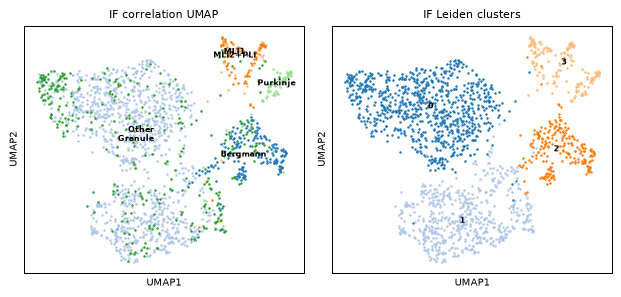

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(7, 3.4))
emb.plot_embedding(takei, "if_umap", "cell_type", ax=axes[0], title="IF correlation UMAP")
emb.plot_embedding(takei, "if_umap", "leiden_if", ax=axes[1], title="IF Leiden clusters")
fig.tight_layout()

top = emb.marker_features(takei, "cell_type", prefix="if.", n_top=3, log=False)   # IF values are z-scores
pd.DataFrame(top).rename_axis("rank")

The IF correlation embedding groups the cerebellar types well above chance, and better than the per-cell
means.  The Leiden clusters give:

- one cluster of Bergmann glia;
- one cluster of the molecular-layer interneurons (MLI1, MLI2+PLI) together with the Purkinje cells;
- two clusters that both mix granule cells with the heterogeneous "Other" group.

So the ARI stays modest.  The published types were derived from the transcriptome, so they are a demanding
reference for chromatin marks alone.  Among the per-cell means, SOX2 comes out for Bergmann glia, which express
it.

## 9. How embeddings are stored

- `cd.cellm[key]`: one array per embedding, with rows aligned with `cd.cells` (`rna_pca`, `rna_umap`,
  `hic_pca`, ...).
- `cd.uns["embeddings"][key]`: what `embed_cells` recorded.  This includes `source`, `modality`, `method`,
  `label` and `axis_prefix`, plus the normalisation, the number of features and their names, and the
  explained variance.  The web browser groups its *Embedding* view by `modality` and labels the axes with
  `axis_prefix`.
- `cd.uns["clusters"][key]`: the Leiden parameters.  The labels themselves are categorical `cd.cells` columns,
  which the browser offers as colourings, like `cell_type`.
- `cd.results`: the gene selection (`"rna.genes"`) and the scHiCluster features (`"hic"`), with the function,
  parameters and version that made them.

All of this round-trips through a `.chromdata.zarr` store.  The cells came from an atlas store, so the link
records point at files that exist only as the atlas store's embedded copies.  `write(path, embed=True)` carries
what the object can reach into the new store, limited to its cells: here the per-cell maps of the 2,000 cells,
so that the web browser can show them.  The pseudo-bulk maps (one per cell type, all 5,313 cells) and the RNA
matrix are not carried: their links are dropped before writing.

In [14]:
pd.DataFrame(cd.uns["embeddings"]).T[["source", "modality", "method", "label", "axis_prefix", "n_features"]]

,source,modality,method,label,axis_prefix,n_features
paper_umap,GSE305439 metadata,Published,umap,Paper UMAP (RNA),UMAP,NaN
rna_pca,rna,RNA,pca,RNA PCA,PC,2000
rna_tsne,rna,RNA,tsne,RNA t-SNE,tSNE,2000
rna_umap,rna,RNA,umap,RNA UMAP,UMAP,2000
atac_lsi,atac,ATAC,lsi,ATAC LSI,LSI,25461
atac_tsne,atac,ATAC,tsne,ATAC t-SNE,tSNE,25461
atac_umap,atac,ATAC,umap,ATAC UMAP,UMAP,25461
hic_pca,hic,Hi-C,pca,Hi-C PCA,PC,400
hic_tsne,hic,Hi-C,tsne,Hi-C t-SNE,tSNE,400
hic_umap,hic,Hi-C,umap,Hi-C UMAP,UMAP,400


In [15]:
path = OUT / "schicar_mop_2000_embeddings.chromdata.zarr"
for family in ("linked_cool", "linked_anndata"):        # the pseudo-bulk maps and the RNA matrix: not carried
    cd.uns.pop(family, None)
cd.write(path, embed=True)                              # embeds the per-cell maps of these 2,000 cells
back = ChromData.read(path)
same = all(np.allclose(back.cellm[k], cd.cellm[k]) for k in cd.cellm)
print(path, "| cellm keys:", sorted(back.cellm), "| arrays equal:", same)
print("clusters:", {k: v["n_clusters"] for k, v in back.uns["clusters"].items()},
      "| embedded maps:", list(back.embedded_links()["contacts"]), "| link problems:", back.validate_links())

# what the web browser lists for this store (the same call its /api/datasets endpoint makes)
from uchrom_browser.data import DatasetStore

store = DatasetStore().load(str(path))
pd.DataFrame(store.embeddings())

_out/schicar_mop_2000_embeddings.chromdata.zarr | cellm keys: ['atac_lsi', 'atac_tsne', 'atac_umap', 'hic_pca', 'hic_tsne', 'hic_umap', 'paper_umap', 'rna_pca', 'rna_tsne', 'rna_umap'] | arrays equal: True
clusters: {'leiden_rna': 17, 'leiden_hic': 5, 'leiden_hic_coarse': 2, 'leiden_atac': 7} | embedded maps: ['per_cell'] | link problems: []


,key,method,source,modality,label,n_dims
0,paper_umap,umap,GSE305439 metadata,Published,Paper UMAP (RNA),2
1,rna_pca,pca,rna,RNA,RNA PCA,30
2,rna_tsne,tsne,rna,RNA,RNA t-SNE,2
3,rna_umap,umap,rna,RNA,RNA UMAP,2
4,atac_lsi,lsi,atac,ATAC,ATAC LSI,30
5,atac_tsne,tsne,atac,ATAC,ATAC t-SNE,2
6,atac_umap,umap,atac,ATAC,ATAC UMAP,2
7,hic_pca,pca,hic,Hi-C,Hi-C PCA,20
8,hic_tsne,tsne,hic,Hi-C,Hi-C t-SNE,2
9,hic_umap,umap,hic,Hi-C,Hi-C UMAP,2


To look at the store interactively, run `python -m uchrom_browser tutorials/_out/schicar_mop_2000_embeddings.chromdata.zarr`.
The *Embedding* view lists the arrays above, grouped by modality, and can colour cells by `cell_type`, the
Leiden columns or any `rna.<gene>`.  The embedded per-cell maps show the (intra-chromosomal) contact map of a
selected cell.

In [16]:
print(f"total runtime {time.time() - T0:.0f} s")

total runtime 401 s


## Next steps

- `higashi_embedding.ipynb`: a contact-map embedding with FastHigashi (tensor decomposition) instead of
  scHiCluster, on sci-Hi-C of two cell lines.
- `plotting_and_browser.ipynb`: the web browser (`uchrom_browser`), which shows the embeddings stored here.
- `chromdata_basics.ipynb` and `chromdata_stores.ipynb`: the `ChromData` container (`cells`, `cellm`, `uns`,
  linked files) and its `.chromdata.zarr` store, including backed reading as used for the Takei data.
- `import_seqfish_multiomics.ipynb`: the Takei 2025 seqFISH+ data: traces, IF tracks and cell types.